---
title: "AI: Large language models"
# Executed once and committed with its outputs. Training the tiny language model takes
# longer than the per-cell limit of scripts/clean_notebooks.py, which therefore leaves
# this notebook alone (see LEAVE_ALONE there). Re-run it by hand after changing any code.
execute:
  enabled: false
format:
  html:
    code-fold: true
    code-summary: "Show the code"
---

![](images/under-construction.png){width=20%}

In [2]:
#| echo: false
#| output: false
%config InlineBackend.figure_formats = ['svg']



In the first week of the course you met the idea that an AI assistant does one small thing over and over: it guesses the next word (@sec-instruction). You now know enough to see how. The assistant is a *large language model*, and a large language model is a neural network of the kind you have met in the last chapters: neurons that weight their inputs, add them up and apply an activation function, arranged in layers and trained by gradient descent and backpropagation. What makes it special is the task it is trained on, the way it turns text into numbers and back, one extra kind of layer that lets it use context, and its size. This chapter takes these in turn, and ends with what they explain about the behavior of the assistant you use.

To make these ideas concrete, the chapter also trains a language model of its own (@sec-llm-tiny). It is a tiny one, with about a hundred thousand parameters, that learns to write text in the style of Shakespeare from a million characters of his plays. It is built in the same way as the models behind AI assistants, only more than a million times smaller, and it trains in a couple of minutes on a laptop. As in the last chapter, the code that produces every figure and every piece of output is folded away, and you can unfold it to see how short it is. scikit-learn has no language models, so this code uses PyTorch, a library for building networks out of layers. Like scikit-learn, it does the backpropagation for you.

## Text as numbers: tokens {#sec-llm-tokens}

A neural network computes with numbers, so the first job is to turn text into numbers. The text is cut into *tokens*, and each token is given a number, its position in a fixed list called the *vocabulary*. A token is often a whole common word, such as "the" or "protein", but rarer words are split into pieces. A word like "phosphorylation" might become "ph", "osph", "ory" and "lation", and a made-up gene name is split into whatever pieces the vocabulary happens to contain. Spaces and punctuation are part of the tokens too. Vocabularies hold from tens of thousands to a few hundred thousand tokens, and the split is chosen once, before training, from how often pieces of text occur. With word pieces, the model can handle any text at all, including words it has never seen.

The consequence is that the model never sees letters. It sees token numbers. A DNA sequence such as `ATGGCCATTGTAATGGGCCGC` reaches it as a handful of chunks of a few letters each, chosen by the tokenizer and not by any biological logic, and the same codon can be cut differently depending on what comes before it. Tasks that are trivial for a three-line Python program, such as counting the Gs in a sequence or writing out its reverse complement, are surprisingly hard for a language model, because the letters it would need to look at are hidden inside tokens. You will test this in the exercises.

The tiny model in @sec-llm-tiny keeps things simpler and uses single characters as tokens.

## Meaning as numbers: embeddings {#sec-llm-embeddings}

A token number on its own says nothing about meaning. Token 4,821 is not more similar to token 4,822 than to token 90,000. So the first layer of the network replaces each token number by a long list of numbers, called its *embedding*. In GPT-3, an early large language model, each embedding has 12,288 numbers ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)). These numbers are weights like any other, set by training, and nobody chooses them.

Training places tokens that are used in similar ways at similar points. Think of each embedding as a position in a space with thousands of directions. "Kinase" ends up near "phosphatase", "mouse" near "rat", and directions in the space come to stand for relations. In an early and much simpler model, the embedding of "king" minus that of "man" plus that of "woman" landed closest to the embedding of "queen" ([Mikolov et al., 2013](https://arxiv.org/abs/1301.3781)). Nobody told the network about royalty or gender. That structure was the most useful way to arrange the words for predicting the text they appear in.

## Predicting the next token {#sec-llm-next}

At the other end of the network sits the output layer, with one output neuron for every token in the vocabulary. Each output neuron produces a score, and the scores are turned into probabilities by softmax, in the same way as the ten scores of the digit network in @sec-digits-output, only with one probability for every token in the vocabulary instead of one for each of ten digits. The result is a probability for every possible next token, as in @fig-llm-next.

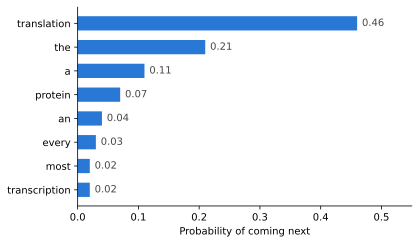

In [3]:
#| label: fig-llm-next
#| fig-cap: "The kind of output a language model produces: a probability for every token in its vocabulary of coming next, here after the text \"The codon ATG marks the start of\". Only the eight most likely tokens are shown. The numbers are made up for illustration and do not come from a real model."
import matplotlib.pyplot as plt

tokens = ["translation", "the", "a", "protein", "an", "every", "most", "transcription"]
probs = [0.46, 0.21, 0.11, 0.07, 0.04, 0.03, 0.02, 0.02]

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.barh(tokens[::-1], probs[::-1], color="#2a78d6", height=0.6)
for bar, p in zip(bars, probs[::-1]):
    ax.text(bar.get_width() + 0.008, bar.get_y() + bar.get_height() / 2, f"{p:.2f}",
            va="center", color="#444444")
ax.set_xlim(0, 0.55)
ax.set_xlabel("Probability of coming next")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The model then picks one token. It could always pick the most likely one, but that tends to produce dull and repetitive text, so it usually *samples*: it draws a token at random, with each token's chance of being drawn equal to its probability. In @fig-llm-next, "translation" would be chosen about half the time, and "transcription", which is wrong here, about one time in fifty. A setting called the *temperature* controls how adventurous the draw is. The scores are divided by the temperature before softmax. A low temperature makes the differences between scores bigger, so the most likely token wins almost every time. A high temperature evens the probabilities out, so unlikely tokens get chosen more often.

The chosen token is added to the end of the text, and the whole thing runs again on the longer text to choose the token after that, and so on, one token at a time, until the model produces a special token that means "the answer is finished". This is how a reply appears word by word on your screen. Nothing in the process looks ahead or plans the whole answer before writing it, beyond what is implicit in the probabilities of the next token.

## Using the context: attention {#sec-llm-attention}

To predict the next token well, the model must take the earlier text into account, and the meaning of a word often depends on words far away from it. "Primer" means one thing in "we bought primer for the wall" and something else in "the primer did not bind because it was too short". In the second sentence, "it" refers to the primer, and to predict what follows, the model needs to know that.

The networks you have met so far treat their inputs as a fixed list and have no natural way to do this. Language models use an additional kind of layer, called *attention*, introduced in an architecture called the *transformer* ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)). The "T" in GPT stands for transformer. In an attention layer, every token looks back at all the tokens before it and decides how relevant each of them is. It does this by computing, from its own embedding, a list of numbers that says what it is looking for, and comparing it with a list that each earlier token computes to say what it contains. The better the match, the higher the relevance score. The scores are turned into weights with softmax, and the token then takes in information from the earlier tokens, mixed in proportion to those weights. In "the primer did not bind because it was too short", the token "it" can learn to attend strongly to "primer" and take in its meaning. How to compute what a token is looking for, what it contains and what it passes on is again set by weights, learned in training like all the others.

A language model stacks many such layers, each followed by an ordinary layer of neurons. GPT-3 has 96 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)). With every layer, each token's list of numbers is refined by what it has gathered from the others, so that by the last layer the list for the final token holds what the model has worked out about the text so far. That list is what the output layer turns into the next-token probabilities. You can see what the attention layers of a small trained model look at in @fig-llm-tiny-attention.

There is a limit to how much text the model can attend to at once, called its *context window*. It has grown from a couple of thousand tokens in early models to hundreds of thousands in recent ones, but text beyond it is simply not seen. This also explains how a chat works. The model has no memory of its own. Each time you send a message, the whole conversation so far, including some instructions from the company that runs the assistant, is fed in as one long text, and the model continues it. When an assistant seems to remember something from earlier in a chat, it is because that part of the chat is still in the text it is reading.

The same architecture works on other kinds of sequences. Protein language models are trained on amino-acid sequences instead of text, with one token per amino acid, and what they learn about which residues go together is enough to predict a protein's three-dimensional structure ([Lin et al., 2023](https://doi.org/10.1126/science.ade2574)).

## How a large language model is trained {#sec-llm-training}

A language model is trained in stages. The first and by far the largest is *pretraining*, and it is the next-token game: show the model a piece of text, let it predict each next token, and use backpropagation to adjust the weights so that the token that actually came next gets a higher probability. The loss is the cross-entropy from @sec-digits-output, a measure of how surprised the model was by the real next token, and training makes it less surprised. The beauty of this game is that the training data needs no labels written by people. Every piece of text supplies its own targets, since the target for each position is just the token that follows it. So the model can be trained on enormous amounts of text: books, websites, articles and a great deal of code. GPT-3, with 175 billion parameters, was trained on several hundred billion tokens ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)). The companies behind current models no longer publish such numbers, but they are larger, and training takes months on tens of thousands of specialized processors.

A pretrained model is a remarkable text continuer, but not an assistant. Given a question, it might continue with three more questions, because that is how lists of questions on the internet continue. The next stage, *fine-tuning*, trains it further on a much smaller set of example conversations written by people, in which a request is followed by a helpful answer. After that, the model's answers are often improved by *reinforcement learning from human feedback*. The model writes several answers to the same request, people rank them from best to worst, and the model is trained toward the kinds of answers people ranked highly ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)).

Through all of this, the model's knowledge consists of its weights and nothing else. There is no database of facts inside it to look things up in. When it states a fact, it is producing text that its weights make likely, and the fact comes out right only because the training text made the correct version likely.

## A tiny language model {#sec-llm-tiny}

Here is the whole process on a scale that fits on a laptop. The training text is about a million characters from Shakespeare's plays, collected by Andrej Karpathy as a [test text for small language models](https://github.com/karpathy/char-rnn). Each character is a token, so the vocabulary is the 65 different characters that occur in the text: the letters, a few punctuation marks, the space, the newline and, for some reason, the digit 3. The first million characters are used for training, and the remaining 115,394 are set aside as test text.

In [4]:
import os, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
torch.manual_seed(0)

# About a million characters of Shakespeare's plays
if not os.path.exists("shakespeare.txt"):
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    urllib.request.urlretrieve(url, "shakespeare.txt")
text = open("shakespeare.txt", encoding="utf-8").read()

chars = sorted(set(text))                            # the vocabulary: every character in the text
to_id = {c: i for i, c in enumerate(chars)}          # each character gets a number
data = torch.tensor([to_id[c] for c in text])
train_data = data[:1000000]                          # the first million characters to train on
test_data = data[1000000:]                           # the rest set aside for testing

print(f"{len(text):,} characters, {len(chars)} different ones:")
print(repr("".join(chars)))
print()
print(text[:240])

1,115,394 characters, 65 different ones:
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to th


Before any neural network, here is the simplest language model there is. Count how often each character is followed by each other character in the training text, and turn each character's counts into probabilities for what comes next. To write text, start with a newline, draw the next character from the probabilities that follow it, and repeat. The output below shows the result. It has learned which letters tend to follow which, that lines are short, and that a newline is often followed by a name in capitals and a colon, but beyond a few short words such as "my" and "hath" it writes no English.

Its loss on the test text, printed at the bottom, is the number to beat. It is the cross-entropy again: minus the logarithm of the probability the model gave to the character that actually came next, averaged over all the characters in the test text. A model that knew nothing and gave all 65 characters the same probability would score $\log 65 \approx 4.17$.

In [5]:
# Count how often each character follows each other character
counts = torch.ones(len(chars), len(chars))          # start at 1, so nothing gets probability 0
counts.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
bigram = counts / counts.sum(dim=1, keepdim=True)    # each row: probabilities of the next character

# Write text by drawing each next character from the row of the previous one
ids = [to_id["\n"]]
for _ in range(300):
    ids.append(torch.multinomial(bigram[ids[-1]], 1).item())
print("".join(chars[i] for i in ids))

# The loss: minus the log of the probability given to the character that actually came next
bigram_loss = -torch.log(bigram[test_data[:-1], test_data[1:]]).mean().item()
print(f"Loss on the test text: {bigram_loss:.2f}")


th remofed hexpselteredoca meaman youd INAlste grecofurey h fotherere hath thig berelisseanongilost.
tho y we w ke RYORD:
Widarthofr nd; my f tsoo we w y mer aim whioervoto,
Pre co n s uzed
I s h. fo INVeprf pllie-milyompofond ssay eint odeld fleome igle inkee he t,
As toinobo y tonesthast st hayowa
Loss on the test text: 2.48


The neural network is a transformer of the kind described in @sec-llm-attention, with every part scaled down. Each character gets an embedding of 64 numbers, and a second embedding is added for its position in the text, because attention by itself does not know which character came first. On top of that sit two layers, each made of an attention layer and an ordinary layer of neurons. Each attention layer has four *heads*: four separate sets of weights that each decide on their own which earlier characters to look at, so that the layer can pay attention to several things at once. The model sees at most 64 characters back, which is its context window. In all it has this many parameters:

In [6]:
class Layer(nn.Module):
    "One transformer layer: attention, then an ordinary layer of neurons."
    def __init__(self, size, heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(size)
        self.attention = nn.MultiheadAttention(size, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(size)
        self.neurons = nn.Sequential(nn.Linear(size, 4 * size), nn.ReLU(), nn.Linear(4 * size, size))

    def forward(self, x):
        n = x.shape[1]
        future = torch.triu(torch.ones(n, n, dtype=torch.bool), diagonal=1)   # no peeking at later characters
        h = self.norm1(x)
        a, self.weights = self.attention(h, h, h, attn_mask=future, average_attn_weights=False)
        x = x + a
        return x + self.neurons(self.norm2(x))

class TinyGPT(nn.Module):
    def __init__(self, vocabulary, context=64, size=64, heads=4, layers=2):
        super().__init__()
        self.context = context
        self.token_embedding = nn.Embedding(vocabulary, size)
        self.position_embedding = nn.Embedding(context, size)
        self.layers = nn.Sequential(*[Layer(size, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(size)
        self.output = nn.Linear(size, vocabulary)

    def forward(self, ids):
        positions = torch.arange(ids.shape[1])
        x = self.token_embedding(ids) + self.position_embedding(positions)
        return self.output(self.norm(self.layers(x)))    # a score for every possible next character

    @torch.no_grad()
    def write(self, start, n, temperature=1.0):
        ids = torch.tensor([[to_id[c] for c in start]])
        for _ in range(n):
            scores = self(ids[:, -self.context:])[0, -1] / temperature
            next_id = torch.multinomial(torch.softmax(scores, dim=0), 1)
            ids = torch.cat([ids, next_id[None]], dim=1)
        return "".join(chars[i] for i in ids[0])

model = TinyGPT(len(chars))
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

112,577 parameters


Training is the next-token game from @sec-llm-training. Each step takes 32 random pieces of 64 characters from the training text. The target for each character is the character that follows it, so each piece gives 64 predictions to learn from at once. The loss is computed, backpropagation finds the slope for every parameter, and every parameter takes a small step downhill. Here is what the model writes after 0, 300, 1,000 and 3,000 such steps.

In [7]:
def batch(data, size):
    "Random pieces of text, and the same pieces one character later as targets."
    starts = torch.randint(len(data) - model.context - 1, (size,))
    x = torch.stack([data[s:s + model.context] for s in starts])
    y = torch.stack([data[s + 1:s + model.context + 1] for s in starts])
    return x, y

@torch.no_grad()
def test_loss():
    x, y = batch(test_data, 512)
    return F.cross_entropy(model(x).transpose(1, 2), y).item()

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
history = []
for step in range(3001):
    if step % 100 == 0:
        history.append((step, test_loss()))
    if step in (0, 300, 1000, 3000):
        print(f"After {step} steps (loss {history[-1][1]:.2f}):")
        print(model.write("\n", 200)[1:])
        print()
    x, y = batch(train_data, 32)
    loss = F.cross_entropy(model(x).transpose(1, 2), y)   # forward pass and loss
    optimizer.zero_grad()
    loss.backward()                                       # backpropagation
    optimizer.step()                                      # a step of gradient descent

After 0 steps (loss 4.33):
ZSKSLe!ly sKZRiuSe!I::&'SUcujUFrIGNNmzROmnSwnKTIxdtYLDUTiw'-g
nCIpkdcIibqxSRPpQk'SCEfwxxEu'x'yEIRvRjcZgUhR?UpSCnOVbbyy ESonCHTB'osBEDHIRkMni&C,;kbch?PmsYSE
qyGidM3h:
ShAq!&
vgcb??Depbqb!jpzU$p&HSFxrZl

After 300 steps (loss 2.22):
HUCHESARDf KIO:
Mo and thit my da brespobe ong.

IVERV:
Themisew.

Chad Seld ud, haynd, hreallered you talwrom y in.
THtee:
Kew ild drit andve aikeen chtale, ss walim hin:
Haghoncll metils artrond ana

After 1000 steps (loss 1.91):
Sesece of me them flect by we come not my
this dise, chant accand him us arm yous of felle,
And aut man from wing again'd your my welse at;
To Rie spervase streself, I deepition:
Arch, sill rooding pl

After 3000 steps (loss 1.76):
Fie, in meanivery friend honour forgeth ir nog,
For bosonions king to thou in at moverdom in gont
To live the citter, his office sips it
Broachent.

ANGELO:
Sincet, No take  Yoreman to acontian's life



At the start, with random weights, the model writes random characters. After 300 steps it has learned about as much as the pair counting: short lines, names in capitals followed by a colon, and a few short words. After 1,000 steps most short words are English words, and after 3,000 the text has the form of a play, with speakers, line breaks and punctuation in about the right places, many real words, and invented ones that sound as if they could be English. It still makes no sense at all. @fig-llm-tiny-loss shows the loss on the test text during training. The model passes the pair counting within the first two hundred steps and ends at 1.76.

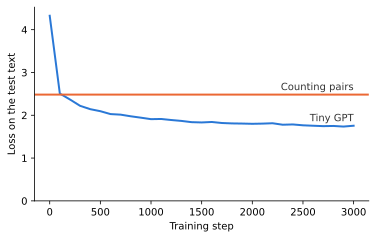

In [8]:
#| label: fig-llm-tiny-loss
#| fig-cap: "The loss of the tiny model on the test text during training (blue), compared with the model that counts pairs of characters (orange)."
steps, losses = zip(*history)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(steps, losses, color="#2a78d6", linewidth=2)
ax.axhline(bigram_loss, color="#eb6834", linewidth=2)
ax.text(3000, losses[-1] + 0.05, "Tiny GPT", ha="right", va="bottom", color="#333333")
ax.text(3000, bigram_loss + 0.05, "Counting pairs", ha="right", va="bottom", color="#333333")
ax.set_xlabel("Training step")
ax.set_ylabel("Loss on the test text")
ax.set_ylim(0, max(losses) + 0.2)
plt.show()

@fig-llm-tiny-attention shows what the eight attention heads look at when the trained model reads the opening of a line by Romeo. Several heads have settled on simple jobs. In the first layer, head 1 puts almost all its weight on the character just before, and head 4 mostly on the character two places back, so that the next layer knows the last few characters in order. Heads 2 and 3 spread their weight over the few characters before. In the second layer the patterns are more varied, and head 4 has found something else: most of the characters after the newline look back at it, the place where the current line began. Nobody designed any of these patterns. They are what the attention weights became because they helped predict the next character.

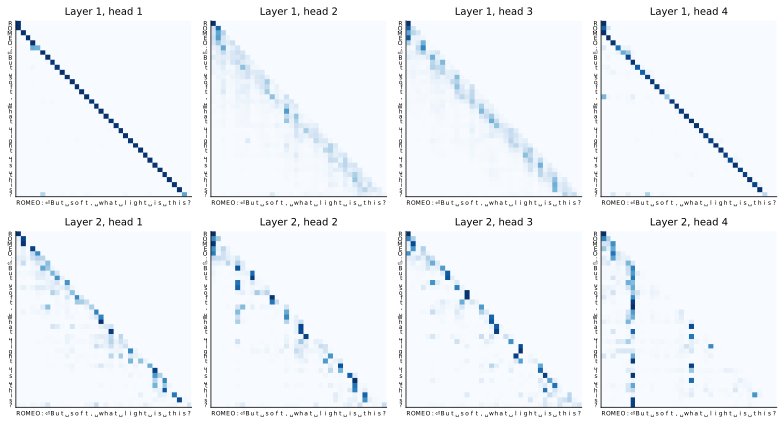

In [9]:
#| label: fig-llm-tiny-attention
#| fig-cap: "The attention weights of the eight heads of the trained tiny model, for the passage shown along the axes (⏎ is the newline and ␣ the space). Each row is one character, and the shading along the row shows how much that character takes in from each of the characters before it. Each row adds up to 1, and everything above the diagonal is 0, because a character cannot look at characters that come after it."
passage = "ROMEO:\nBut soft, what light is this?"
with torch.no_grad():
    model(torch.tensor([[to_id[c] for c in passage]]))   # run the model once; each layer keeps its attention weights

labels = [{"\n": "⏎", " ": "␣"}.get(c, c) for c in passage]
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for layer in range(2):
    for head in range(4):
        ax = axes[layer, head]
        ax.imshow(model.layers[layer].weights[0, head], cmap="Blues", vmin=0, vmax=1)
        ax.set_title(f"Layer {layer + 1}, head {head + 1}", fontsize=10)
        ax.set_xticks(range(len(passage)), labels, fontsize=6)
        ax.set_yticks(range(len(passage)), labels, fontsize=6)
        ax.tick_params(length=0)
plt.tight_layout()
plt.show()

With training done, the temperature from @sec-llm-next can be tried out. Below are three samples, at temperatures 0.5, 1.0 and 1.5. At 0.5 the model sticks to its most likely characters, and nearly every word is a real one, though the sentences are still nonsense. At 1.5, unlikely characters are drawn often, and the text falls apart into invented words and stray capitals.

In [10]:
for temperature in (0.5, 1.0, 1.5):
    print(f"Temperature {temperature}:")
    print(model.write("\n", 300, temperature)[1:])
    print()

Temperature 0.5:
The will against that much poor of the sent with the peoperson not she
waker, and the command.

First Murderer:
To me the courts so good beam upon a for their anot.

CAMILLO:
The heart of the being and many will persign and with where to the word words
And his in the grown for most, and bound my lor

Temperature 1.0:
Firsue, very possibunel,--
Tell, bid old him, please some the persuant had heart.

WARBELLA:
Till good in the drudion; should
For Boints Roman it to minest, his laful of the cendure.

DUKE:
O, for the wagaing thing indoster:
To's morrows.

KING LEW:
Hom art Look dead, weepher, dome be the well.

ROM

Temperature 1.5:

A marry thide.'
all, my upon. O!
Mind-pross' Was yourstely cudsu, accasumfotle.
Say, do to I course?
Thpy naius;.
3ookecvy'd,-gher which in Julittle.

CAMULO:

ChorETd'sbRCHiddneraito in'tve goand powk ut.

CAMILLO:
Vongeaughbed into him: like in fool, the mother;
Ourse's you, light, your viceladut



Training also shaped the embeddings. @fig-llm-tiny-embedding squeezes each character's 64 numbers down to two and draws every character at the resulting position. Characters used in similar ways have ended up roughly near each other. Most lowercase letters gather in one region, most capital letters, which in this text mostly spell the names of speakers, in another, and the punctuation marks that end or break up a sentence on the far right. Nobody told the model which characters are letters, capitals or punctuation. Two numbers out of 64 give a crowded picture, and some characters do not follow the pattern, but this is the same thing that happens to word pieces in large models, in thousands of directions instead of two.

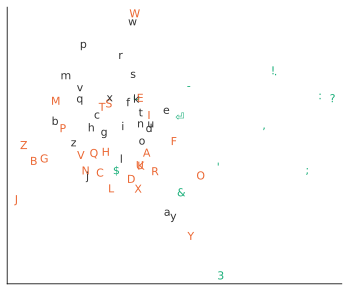

In [11]:
#| label: fig-llm-tiny-embedding
#| fig-cap: "The embeddings of the 65 characters in the trained tiny model, each squeezed from 64 numbers to the two that differ most between characters, and drawn at that position. Capital letters are orange, lowercase letters gray, and punctuation, the digit 3, the space (␣) and the newline (⏎) green."
# Squeeze the 64 numbers of each character's embedding down to the two that vary most
E = model.token_embedding.weight.detach().numpy()
E = E - E.mean(axis=0)
_, _, directions = np.linalg.svd(E, full_matrices=False)
xy = E @ directions[:2].T

fig, ax = plt.subplots(figsize=(6, 5))
for c, (x, y) in zip(chars, xy):
    color = "#eb6834" if c.isupper() else "#333333" if c.islower() else "#1baf7a"
    ax.text(x, y, {"\n": "⏎", " ": "␣"}.get(c, c), ha="center", va="center", color=color, fontsize=11)
ax.set_xlim(xy[:, 0].min() - 0.3, xy[:, 0].max() + 0.3)
ax.set_ylim(xy[:, 1].min() - 0.3, xy[:, 1].max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
plt.show()

That is the whole recipe. The language model behind an AI assistant is built in the same way, with word pieces instead of characters, around a hundred layers instead of two, thousands of numbers in each embedding instead of 64, and hundreds of billions of tokens of training text instead of a million characters, followed by the fine-tuning and human feedback described in @sec-llm-training. The tiny model also shows something about the large ones. After a couple of minutes of training it writes text that looks like Shakespeare and means nothing, because looking right is all the loss rewards. The large models are vastly better at it, and that is both what makes them useful and what the next section is about.

## What this explains {#sec-llm-explains}

Most of the behavior of an AI assistant that surprises people follows directly from how it works.

It produces plausible text, and plausible text is not always true. Pretraining rewards predicting what text is likely to come next, and a false statement can be very likely: a reasonable-sounding function for a gene that was never studied, a reference to a paper that would fit perfectly but does not exist, a codon table with one quiet mistake. The model has no separate sense of whether a statement is true, so it states false things in the same fluent, confident tone as true ones. This is what is called *hallucination*.

It knows nothing after its training data was collected, unless something newer is put into its context, for example by a web search that the assistant runs and pastes into the conversation before answering. Modern assistants use such tools, and they can also run code, which helps a great deal. But the final answer is still written token by token by the model, which can misread or misreport what the tool returned.

It struggles with letters inside tokens, which is why it can miscount the bases in a sequence or get a reverse complement wrong while explaining correctly how a reverse complement is made.

It can give different answers to the same question, because each token is drawn at random from the probabilities. If you ask twice and get two different answers, at least one of them did not come from knowing the answer.

It tends to agree with you. The human feedback that made it helpful also rewards answers people like, and people like being agreed with. Language models trained this way have been shown to go along with a user's mistaken belief, and to give up a correct answer when the user pushes back ([Sharma et al., 2023](https://arxiv.org/abs/2310.13548)). That the assistant agrees with you is not evidence that you are right.

None of this makes the assistant less useful. A system trained on a large part of everything people have written, and able to combine it fluently for exactly your question, is extraordinary. It means that the assistant's answers are proposals. As you have learned throughout the course, a proposal becomes something you can rely on when you have checked it: by running the code, by a test, or against the documentation or the literature.

#### Exercise

[AI: Explainer](../intro/course-introduction.qmd#sec-badge-explainer){.small}

Give the assistant this sequence and ask it two things: how many times the base G occurs in it, and what its reverse complement is. Ask it not to use any tools or run any code, so that you test the model itself.

```
ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG
```

Then settle both answers yourself with a short Python program that you write without help. Count the Gs with a string method, and build the reverse complement with a dictionary and a loop, or any other way you know. Compare letter by letter. Then ask the assistant again, this time allowing it to run code, and compare once more.

::: {.callout-tip collapse="true" appearance="minimal" icon=false}

## Why can the assistant get this wrong?

It never sees the individual bases, only tokens of several letters each, so counting letters and reversing them base by base is exactly the kind of task its input hides from it. When it runs code, it is no longer doing the task itself: Python does the counting, and the model only writes the program and reports the result, which is far more reliable. If its first answers were right, try a longer sequence. The longer the sequence, the more likely the model is to slip.
:::

<br>

#### Exercise

[SOLO](../intro/course-introduction.qmd#sec-badge-solo){.small}

Suppose a model gives three possible next tokens the scores 2, 1 and 0. Use Python, with `math.exp` from the `math` module, to compute the softmax probabilities (@sec-digits-output). Then divide the scores by a temperature of 0.5 and compute them again. Before you compute the second set, predict whether the most likely token becomes more or less likely.

::: {.callout-tip collapse="true" appearance="minimal" icon=false}

## What are the probabilities at the original scores?

$e^2 \approx 7.39$, $e^1 \approx 2.72$ and $e^0 = 1$, which add up to about $11.11$. The probabilities are about $0.67$, $0.24$ and $0.09$.
:::

::: {.callout-tip collapse="true" appearance="minimal" icon=false}

## What happens at temperature 0.5?

The scores become 4, 2 and 0. $e^4 \approx 54.6$, $e^2 \approx 7.39$ and $e^0 = 1$ add up to about $63.0$, so the probabilities are about $0.87$, $0.12$ and $0.02$. The most likely token became more likely, and the least likely one almost disappeared. A low temperature makes the model more predictable. Try a temperature of 2 as well, and you will see the probabilities even out.
:::

<br>

#### Exercise

[AI: Explainer](../intro/course-introduction.qmd#sec-badge-explainer){.small}

Open two fresh conversations with the assistant and ask both, word for word, the same question: "In two sentences, what does the human gene TP53 do?" Put the two answers side by side. Then check every factual claim in them against the gene's entry in [NCBI Gene](https://www.ncbi.nlm.nih.gov/gene/7157) or [UniProt](https://www.uniprot.org/uniprotkb/P04637/entry). Do the two answers say the same things in different words, or do they make different claims? Repeat the experiment with a gene that is much less studied, picked from a list of genes in one of your courses, and note in your logbook whether the answers became less consistent, and whether the database agreed with them.

::: {.callout-tip collapse="true" appearance="minimal" icon=false}

## What should you expect?

For TP53, one of the most studied genes there is, the two answers will probably differ in wording but agree in substance, because the training text says the same things about it over and over, so the most likely tokens are the right ones. For an obscure gene, there is little training text, the probabilities are spread more evenly, and the sampled answers can differ in what they claim and may describe functions the database does not support. The tone of the answers will not tell you which case you are in. Only the database can.
:::